# Can DET combined with another RQA measure gauge predictability?

**Question.** DET alone is not a predictability measure. Does DET combined with a second recurrence statistic track the *actual* predictability of a system, across chaotic and stochastic systems?

**Design.**
- **Systems with known behaviour:** logistic map over r (exact λ), Lorenz-63 with observation noise and different sampling steps, AR(1) over φ (exact best-forecast skill), GARCH(1,1) returns and |returns|, two coupled Rössler oscillators (single vs joint recurrence).
- **Actual predictability (target):** $\text{skill}(h) = 1 - \text{MSE}(h)/\text{Var}$ for $h = 1..40$ of the best available forecaster:
  - exact theory where the model gives it: AR(1) $\phi^{2h}$; GARCH returns 0; GARCH |returns| = true-model volatility (r²) forecast skill;
  - otherwise a model-free nearest-neighbour (method-of-analogues) forecaster on held-out data (logistic, Lorenz, Rössler). The analogue skill is also reported for every case (`S_knn`) as a check.
  - Summaries: mean skill over the 40 steps (`S`) and the first step where skill drops below 0.5 (`H50`).
- **Recurrence measures:** Euclidean RP of one 1,000-point window, recurrence rate fixed at 5% (Theiler window 1). Measures: DET, L, ENTR, LAM, `DET3_DET2` = DET(lmin = 3)/DET(lmin = 2), and `K2_lines`, the per-step decay rate of the share of pairs that stay recurrent for l steps. For IID data `K2_lines` equals −ln RR ≈ 3.0; for chaos it estimates the K₂ entropy (Thiel et al. 2003).
- **Null:** each measure is also computed on a shuffled copy of the same window (same embedding, same RR). `*_excess` = shuffled − actual for `K2_lines`, and actual − shuffled for the others. This removes what embedding and the threshold produce on their own.
- **Baselines:** permutation entropy (order 4) and lag-1 autocorrelation.
- **Combination test:** leave one system family out, fit skill ~ features on the rest, predict the held-out family.

In [1]:
import time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.precision", 3)

## Recurrence measures

In [2]:
import numpy as np, pandas as pd
from scipy.stats import spearmanr

RR_TARGET, THEILER, LMINS = 0.05, 1, np.arange(2, 8)

def embed(x, m, tau):
    x = np.asarray(x, float)
    if x.ndim == 1: x = x[:, None]
    n = len(x) - (m - 1) * tau
    return np.concatenate([x[k * tau:k * tau + n] for k in range(m)], axis=1)

def recurrence_matrix(states, rr=RR_TARGET, theiler=THEILER):
    """Euclidean RP with the threshold set so the off-Theiler recurrence rate equals rr."""
    d = np.sqrt(((states[:, None, :] - states[None, :, :]) ** 2).sum(-1))
    n = len(d)
    band = np.abs(np.arange(n)[:, None] - np.arange(n)[None, :]) < theiler
    eps = np.quantile(d[np.triu_indices(n, theiler)], rr)
    R = d <= eps
    R[band] = False
    return R

def _runs(seqs):
    out = []
    for s in seqs:
        s = np.concatenate([[0], s.astype(np.int8), [0]])
        dd = np.diff(s)
        out.append(np.flatnonzero(dd == -1) - np.flatnonzero(dd == 1))
    return np.concatenate(out) if out else np.array([], int)

def line_lengths(R):
    n = len(R)
    diag = _runs(np.diagonal(R, k) for k in range(1, n))   # upper triangle; RP is symmetric
    vert = _runs(R[:, j] for j in range(n))
    return diag, vert

def k2_lines(diag, n, ls=np.arange(1, 7), min_count=10):
    """Per-step decay rate of C_l, the share of pairs that stay recurrent for l consecutive steps.
    For IID data C_l = RR**l, so the rate is -ln(RR); for chaos it estimates K2 (Thiel et al. 2003)."""
    counts = np.array([np.clip(diag - l + 1, 0, None).sum() for l in ls], float)
    pairs = np.array([sum(max(n - k - l + 1, 0) for k in range(1, n)) for l in ls], float)
    ok = counts >= min_count
    if ok.sum() < 3:
        return np.nan
    return -np.polyfit(ls[ok], np.log(counts[ok] / pairs[ok]), 1)[0]

def rqa(R):
    diag, vert = line_lengths(R)
    pts = diag.sum()
    det = lambda lmin: diag[diag >= lmin].sum() / pts
    long = diag[diag >= 2]
    p = np.bincount(long)[2:]; p = p[p > 0] / p.sum()
    return {"RR": R.mean(), "DET": det(2), "L": long.mean() if len(long) else 0.0,
            "ENTR": float(-(p * np.log(p)).sum()) if len(p) else 0.0,
            "LAM": vert[vert >= 2].sum() / max(vert.sum(), 1),
            "DET3_DET2": det(3) / max(det(2), 1e-12), "K2_lines": k2_lines(diag, len(R))}

def joint_matrix(state_list, rr=RR_TARGET, theiler=THEILER):
    R = recurrence_matrix(state_list[0], rr, theiler)
    for s in state_list[1:]:
        R = R & recurrence_matrix(s, rr, theiler)
    return R

def permutation_entropy(x, order=4, delay=1):
    x = np.asarray(x, float)
    n = len(x) - (order - 1) * delay
    patterns = np.argsort(np.stack([x[k * delay:k * delay + n] for k in range(order)], 1), 1)
    _, counts = np.unique(patterns, axis=0, return_counts=True)
    p = counts / counts.sum()
    from math import factorial
    return float(-(p * np.log(p)).sum() / np.log(factorial(order)))

## Systems and the predictability target

In [3]:
WINDOW, TRAIN, HORIZON = 1000, 6000, 40

def logistic_series(r, n, rng, burn=1000):
    x, out = rng.uniform(0.2, 0.8), np.empty(n)
    for i in range(burn + n):
        x = r * x * (1 - x)
        if i >= burn: out[i - burn] = x
    return out

def logistic_lyapunov(r, n=50000, seed=0):
    x = logistic_series(r, n, np.random.default_rng(seed))
    return float(np.mean(np.log(np.abs(r * (1 - 2 * x)) + 1e-300)))

def rk4(f, s, dt, n, sub=1):
    out = np.empty((n, len(s)))
    h = dt / sub
    for i in range(n):
        for _ in range(sub):
            k1 = f(s); k2 = f(s + h / 2 * k1); k3 = f(s + h / 2 * k2); k4 = f(s + h * k3)
            s = s + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        out[i] = s
    return out

def lorenz_series(n, rng, dt=0.05, burn=2000):
    f = lambda s: np.array([10 * (s[1] - s[0]), s[0] * (28 - s[2]) - s[1], s[0] * s[1] - 8 / 3 * s[2]])
    s = rk4(f, rng.normal(0, 1, 3) + [1, 1, 20], dt, burn + n, sub=5)[burn:]
    return s[:, 0]

def ar1_series(phi, n, rng, burn=500):
    e, x = rng.standard_normal(n + burn), np.zeros(n + burn)
    for t in range(1, n + burn): x[t] = phi * x[t - 1] + e[t]
    return x[burn:]

def garch_series(persistence, n, rng, alpha=0.08, burn=2000):
    beta = persistence - alpha; omega = 1 - persistence          # unconditional variance = 1
    z, r = rng.standard_normal(n + burn), np.empty(n + burn)
    s2 = 1.0
    for t in range(n + burn):
        r[t] = np.sqrt(s2) * z[t]
        s2 = omega + alpha * r[t] ** 2 + beta * s2
    return r[burn:]

def coupled_rossler(mu, n, rng, dt=1.0, nu=0.02, burn=500):
    w1, w2 = 1 + nu, 1 - nu
    def f(s):
        x1, y1, z1, x2, y2, z2 = s
        return np.array([-w1 * y1 - z1 + mu * (x2 - x1), w1 * x1 + 0.2 * y1, 0.2 + z1 * (x1 - 5.7),
                         -w2 * y2 - z2 + mu * (x1 - x2), w2 * x2 + 0.2 * y2, 0.2 + z2 * (x2 - 5.7)])
    s = rk4(f, rng.normal(0, 1, 6) + [1, 0, 0, -1, 0, 0], dt, burn + n, sub=max(4, int(round(dt / 0.05))))[burn:]
    return s[:, [0, 1, 3, 4]]   # x1, y1, x2, y2

def analogue_skill(train, test, m, tau, horizon=HORIZON, k=10, n_query=400):
    """Model-free predictability: nearest-neighbour (method of analogues) forecasts on held-out data.
    Returns skill(h) = 1 - MSE(h)/Var for h = 1..horizon, using the same embedding as the RP."""
    train, test = np.atleast_2d(train.T).T, np.atleast_2d(test.T).T
    mu, sd = train.mean(0), train.std(0)
    train, test = (train - mu) / sd, (test - mu) / sd
    lib = embed(train, m, tau)[:-horizon]
    lib_t0 = np.arange(len(lib)) + (m - 1) * tau
    q_all = embed(test, m, tau)[:-horizon]
    q_idx = np.linspace(0, len(q_all) - 1, n_query).astype(int)
    q_t0 = q_idx + (m - 1) * tau
    d = ((q_all[q_idx][:, None, :] - lib[None]) ** 2).sum(-1)
    nn = np.argpartition(d, k, axis=1)[:, :k]
    skill = []
    for h in range(1, horizon + 1):
        pred = train[lib_t0[nn] + h].mean(1)
        err = ((pred - test[q_t0 + h]) ** 2).sum(-1).mean()
        skill.append(1 - err / test.shape[1])
    return np.array(skill)

def ar1_theory_skill(phi, horizon=HORIZON):
    """Best possible skill for AR(1): the conditional mean phi**h * x_t explains phi**(2h) of the variance."""
    return phi ** (2 * np.arange(1, horizon + 1))

_garch_cache = {}
def garch_oracle_skill(persistence, alpha=0.08, horizon=HORIZON, n=200_000, seed=0):
    """Skill of the true-model forecast of r**2 (volatility), estimated on one long simulation."""
    if persistence in _garch_cache:
        return _garch_cache[persistence]
    rng = np.random.default_rng(seed)
    beta, omega, burn = persistence - alpha, 1 - persistence, 2000
    z, r, s2 = rng.standard_normal(n + burn), np.empty(n + burn), np.empty(n + burn + 1)
    s2[0] = 1.0
    for t in range(n + burn):
        r[t] = np.sqrt(s2[t]) * z[t]
        s2[t + 1] = omega + alpha * r[t] ** 2 + beta * s2[t]
    r2, s2 = r[burn:] ** 2, s2[burn:]
    skill = []
    for h in range(1, horizon + 1):
        pred = 1 + persistence ** (h - 1) * (s2[1:len(r2) - h + 1] - 1)   # E[r2[t+h] | info at t]
        skill.append(1 - np.mean((r2[h:] - pred) ** 2) / r2.var())
    _garch_cache[persistence] = np.array(skill)
    return _garch_cache[persistence]

## Experiment grid

Each case is one parameter setting and one random seed. Training data (6,000 points) and the test window (1,000 points) come from the same realisation, with the window immediately after the training block.

In [4]:
SEEDS = range(3)

def cases():
    for seed in SEEDS:
        for r in np.linspace(3.5, 4.0, 26):
            yield dict(family="logistic", param=round(r, 3), seed=seed, m=1, tau=1)
        for noise in [0, 0.02, 0.05, 0.1, 0.2, 0.5]:
            yield dict(family="lorenz_noise", param=noise, seed=seed, m=3, tau=2)
        for dt in [0.02, 0.05, 0.1]:
            yield dict(family="lorenz_dt", param=dt, seed=seed, m=3, tau=max(1, round(0.1 / dt)))
        for phi in [0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99]:
            yield dict(family="ar1", param=phi, seed=seed, m=1, tau=1)
        for p in [0.5, 0.8, 0.9, 0.95, 0.98, 0.995]:
            yield dict(family="garch_returns", param=p, seed=seed, m=2, tau=1)
            yield dict(family="garch_abs", param=p, seed=seed, m=2, tau=1)
        for mu in [0, 0.01, 0.02, 0.03, 0.04, 0.06, 0.08, 0.1]:
            yield dict(family="rossler_single", param=mu, seed=seed, m=3, tau=1)
            yield dict(family="rossler_joint", param=mu, seed=seed, m=3, tau=1)

def generate(c):
    rng = np.random.default_rng(1000 * c["seed"] + sum(map(ord, c["family"])))
    n = TRAIN + WINDOW + HORIZON
    f, p = c["family"], c["param"]
    lam = np.nan
    if f == "logistic":
        x = logistic_series(p, n, rng); lam = logistic_lyapunov(p)
    elif f == "lorenz_noise":
        x = lorenz_series(n, rng); x = x + p * x.std() * rng.standard_normal(n); lam = 0.906 * 0.05
    elif f == "lorenz_dt":
        x = lorenz_series(n, rng, dt=p); lam = 0.906 * p
    elif f == "ar1":
        x = ar1_series(p, n, rng)
    elif f.startswith("garch"):
        x = garch_series(p, n, rng); x = np.abs(x) if f == "garch_abs" else x
    else:
        x = coupled_rossler(p, n, rng)          # columns x1, y1, x2, y2
    return x, lam

def phase_locking(xy):
    ph1, ph2 = np.unwrap(np.arctan2(xy[:, 1], xy[:, 0])), np.unwrap(np.arctan2(xy[:, 3], xy[:, 2]))
    return float(np.abs(np.exp(1j * (ph1 - ph2)).mean()))

def evaluate(c, rng):
    x, lam = generate(c)
    m, tau = c["m"], c["tau"]
    train, window = x[:TRAIN], x[TRAIN:TRAIN + WINDOW + HORIZON]
    w = window[:WINDOW]
    row = dict(c, lam_per_step=lam)
    if c["family"].startswith("rossler"):
        row["phase_locking"] = phase_locking(w)
        if c["family"] == "rossler_joint":
            states = [embed(w[:, 0], m, tau), embed(w[:, 2], m, tau)]
            R = joint_matrix(states)
            perm = rng.permutation(WINDOW)
            R0 = joint_matrix([embed(w[perm, 0], m, tau), embed(w[perm, 2], m, tau)])
            skill = analogue_skill(train[:, [0, 2]], window[:, [0, 2]], m, tau)
            scalar = w[:, 0]
        else:
            R, perm = recurrence_matrix(embed(w[:, 0], m, tau)), rng.permutation(WINDOW)
            R0 = recurrence_matrix(embed(w[perm, 0], m, tau))
            skill = analogue_skill(train[:, 0], window[:, 0], m, tau)
            scalar = w[:, 0]
    else:
        R = recurrence_matrix(embed(w, m, tau))
        R0 = recurrence_matrix(embed(rng.permutation(w), m, tau))
        skill = analogue_skill(train, window, m, tau)
        scalar = w
    actual, null = rqa(R), rqa(R0)
    row.update(actual)
    for k in ["DET", "L", "ENTR", "LAM", "DET3_DET2"]:
        row[k + "_excess"] = actual[k] - null[k]
    row["K2_excess"] = null["K2_lines"] - actual["K2_lines"]
    row["PE"] = permutation_entropy(scalar)
    row["ACF1"] = float(np.corrcoef(scalar[:-1], scalar[1:])[0, 1])
    row["S_knn"] = float(np.clip(skill, 0, None).mean())
    # Target: exact best-possible skill where the model gives it, analogue forecaster otherwise.
    if c["family"] == "ar1":
        skill = ar1_theory_skill(c["param"])
    elif c["family"] == "garch_returns":
        skill = np.zeros(HORIZON)                  # returns are a martingale difference: nothing to predict
    elif c["family"] == "garch_abs":
        skill = garch_oracle_skill(c["param"])     # volatility (r**2) predictability of the true model
    row["target"] = "theory" if c["family"] in ("ar1", "garch_returns", "garch_abs") else "analogue"
    row["S"] = float(np.clip(skill, 0, None).mean())
    below = np.flatnonzero(skill < 0.5)
    row["H50"] = int(below[0]) if len(below) else HORIZON
    row["skill_h1"] = float(skill[0])
    return row

t0 = time.time()
rng = np.random.default_rng(2026)
results = pd.DataFrame([evaluate(c, rng) for c in cases()])
print(f"{len(results)} cases in {time.time() - t0:.0f} s")
results.to_csv("../../results/tables/det_predictability_results.csv", index=False)

213 cases in 181 s


## Sanity checks

These must hold before any result is trusted.

In [5]:
checks = []
iid = results.query("family == 'ar1' and param == 0")
checks.append(("IID (AR φ=0, m=1): K2_lines ≈ −ln RR = 3.00", iid["K2_lines"].mean()))
checks.append(("IID: analogue S_knn ≈ 0 (theory 0)", iid["S_knn"].mean()))
lg4 = results.query("family == 'logistic' and param == 4.0")
checks.append(("Logistic r=4: λ = ln 2 = 0.693", lg4["lam_per_step"].mean()))
checks.append(("Logistic r=4: K2_lines (K2 ≤ λ, finite-ε bias upward)", lg4["K2_lines"].mean()))
for phi in [0.6, 0.9, 0.99]:
    a = results.query("family == 'ar1' and param == @phi")
    checks.append((f"AR φ={phi}: analogue S_knn vs theory S = {a['S'].mean():.3f}", a["S_knn"].mean()))
gr = results.query("family == 'garch_returns'")
checks.append(("GARCH returns: analogue S_knn ≈ 0 (direction unpredictable)", gr["S_knn"].mean()))
ga = results.query("family == 'garch_abs' and param == 0.995")
checks.append(("GARCH persistence 0.995: true-model volatility skill S", ga["S"].mean()))
display(pd.DataFrame(checks, columns=["check", "value"]))

,check,value
0,"IID (AR φ=0, m=1): K2_lines ≈ −ln RR = 3.00",2.961e+00
1,IID: analogue S_knn ≈ 0 (theory 0),1.774e-04
2,Logistic r=4: λ = ln 2 = 0.693,6.932e-01
3,"Logistic r=4: K2_lines (K2 ≤ λ, finite-ε bias ...",6.931e-01
4,AR φ=0.6: analogue S_knn vs theory S = 0.014,6.595e-03
5,AR φ=0.9: analogue S_knn vs theory S = 0.107,6.475e-02
6,AR φ=0.99: analogue S_knn vs theory S = 0.680,5.498e-01
7,GARCH returns: analogue S_knn ≈ 0 (direction u...,1.776e-02
8,GARCH persistence 0.995: true-model volatility...,1.387e-01


## Per-family rank correlation with actual predictability (S)

In [6]:
measures = ["DET", "L", "ENTR", "LAM", "DET3_DET2", "K2_lines",
            "DET_excess", "LAM_excess", "K2_excess", "PE", "ACF1"]
per_family = (results.groupby("family")
              [measures + ["S"]].apply(lambda g: pd.Series({k: g[k].corr(g["S"], method="spearman") for k in measures}))
              .round(2))
per_family.loc["pooled"] = [results[k].corr(results["S"], method="spearman") for k in measures]
display(per_family.round(2))

chaotic = results[results["lam_per_step"] > 0.02]
print("Chaotic cases only (logistic + Lorenz), Spearman with λ per step:")
display(pd.Series({k: chaotic[k].corr(chaotic["lam_per_step"], method="spearman") for k in measures}).round(2))

C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,DET,L,ENTR,LAM,DET3_DET2,K2_lines,DET_excess,LAM_excess,K2_excess,PE,ACF1
family,,,,,,,,,,,
ar1,0.99,0.95,0.95,0.99,0.95,-0.97,0.99,0.97,0.93,-0.95,0.99
garch_abs,0.78,0.77,0.76,0.62,0.76,-0.85,0.91,0.17,0.59,0.29,0.86
garch_returns,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
logistic,0.67,0.97,0.87,-0.75,0.96,-0.96,0.36,-0.60,-0.07,-0.92,-0.82
lorenz_dt,0.93,0.90,0.90,0.92,0.88,-0.90,0.95,0.93,0.93,-0.88,0.92
lorenz_noise,0.97,0.97,0.95,0.88,0.81,-0.98,0.97,0.82,0.92,-0.94,0.96
rossler_joint,0.89,0.90,0.83,0.62,0.85,-0.91,-0.15,0.69,-0.59,-0.70,0.58
rossler_single,0.29,0.60,-0.93,0.90,0.58,-0.66,0.19,0.79,0.61,0.38,-0.64
pooled,0.88,0.93,0.89,-0.52,0.94,-0.93,0.66,-0.40,0.54,-0.75,-0.10


Chaotic cases only (logistic + Lorenz), Spearman with λ per step:


DET          -0.41
L            -0.75
ENTR         -0.70
LAM          -0.44
DET3_DET2    -0.69
K2_lines      0.71
DET_excess   -0.31
LAM_excess   -0.55
K2_excess     0.34
PE            0.39
ACF1         -0.27
dtype: float64

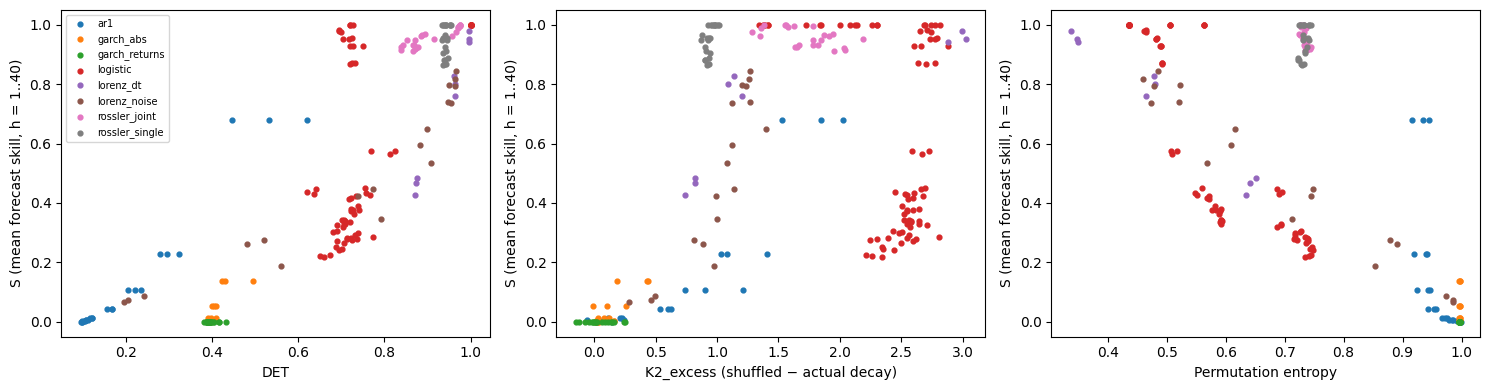

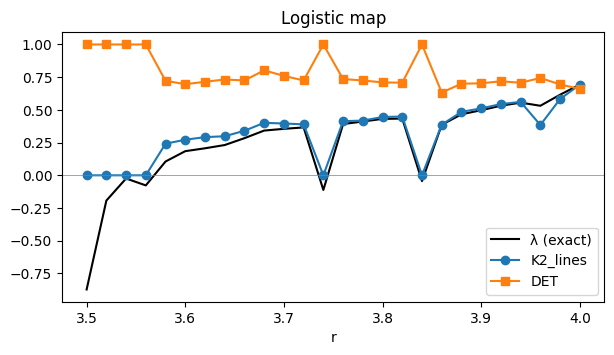

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for fam, g in results.groupby("family"):
    axes[0].scatter(g["DET"], g["S"], s=12, label=fam)
    axes[1].scatter(g["K2_excess"], g["S"], s=12)
    axes[2].scatter(g["PE"], g["S"], s=12)
for ax, lab in zip(axes, ["DET", "K2_excess (shuffled − actual decay)", "Permutation entropy"]):
    ax.set(xlabel=lab, ylabel="S (mean forecast skill, h = 1..40)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

lg = results.query("family == 'logistic'").groupby("param").mean(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(lg.index, lg["lam_per_step"], "k-", label="λ (exact)")
ax.plot(lg.index, lg["K2_lines"], "o-", label="K2_lines")
ax.plot(lg.index, lg["DET"], "s-", label="DET")
ax.axhline(0, color="grey", lw=0.5); ax.set(xlabel="r", title="Logistic map"); ax.legend()
plt.show()

## Combination test: leave one family out

For each feature set, fit a linear model of `S` on the other families and predict the held-out one. Reported: Spearman ρ between predicted and actual `S` inside the held-out family (does it rank settings correctly?) and pooled out-of-family RMSE (is it on the right scale?). The Rössler families are scored together, so the joint and single versions of the same system are never split between training and test.

In [8]:
from numpy.linalg import lstsq
feature_sets = {
    "DET": ["DET"], "DET + LAM": ["DET", "LAM"], "DET + ENTR": ["DET", "ENTR"], "DET + L": ["DET", "L"],
    "DET + DET3/DET2": ["DET", "DET3_DET2"], "K2_lines": ["K2_lines"],
    "DET_excess + LAM_excess": ["DET_excess", "LAM_excess"], "K2_excess": ["K2_excess"],
    "K2_excess + LAM_excess": ["K2_excess", "LAM_excess"],
    "PE (baseline)": ["PE"], "ACF1 (baseline)": ["ACF1"], "PE + K2_excess": ["PE", "K2_excess"],
}
data = results.dropna(subset=sum(feature_sets.values(), [])).copy()
data["group"] = data["family"].str.replace("_single|_joint", "", regex=True).str.replace("_noise|_dt", "", regex=True)
rows = []
for name, cols in feature_sets.items():
    preds = pd.Series(index=data.index, dtype=float)
    for grp in data["group"].unique():
        tr, te = data[data.group != grp], data[data.group == grp]
        A = np.c_[np.ones(len(tr)), tr[cols]]
        coef = lstsq(A, tr["S"], rcond=None)[0]
        preds[te.index] = np.c_[np.ones(len(te)), te[cols]] @ coef
    rho = {g: preds[d.index].corr(d["S"], method="spearman") for g, d in data.groupby("group")}
    rows.append({"features": name, **{f"rho_{g}": v for g, v in rho.items()},
                 "mean_rho": np.nanmean(list(rho.values())),
                 "RMSE_out_of_family": float(np.sqrt(((preds - data["S"]) ** 2).mean()))})
combo = pd.DataFrame(rows).set_index("features").sort_values("mean_rho", ascending=False)
display(combo.round(2))

C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: Constan

,rho_ar1,rho_garch_abs,rho_garch_returns,rho_logistic,rho_lorenz,rho_rossler,mean_rho,RMSE_out_of_family
features,,,,,,,,
K2_lines,0.97,0.85,NaN,0.96,0.98,0.68,0.89,0.39
DET + DET3/DET2,0.97,0.80,NaN,0.88,0.91,0.63,0.84,0.26
DET + L,0.99,0.79,NaN,0.88,0.97,0.54,0.83,4.47
DET,0.99,0.78,NaN,0.67,0.97,0.52,0.79,0.25
DET + LAM,0.99,0.81,NaN,0.69,0.98,0.43,0.78,0.26
DET + ENTR,0.99,0.77,NaN,0.80,0.98,0.06,0.72,0.26
DET_excess + LAM_excess,0.86,0.80,NaN,0.68,0.82,-0.16,0.60,0.46
PE (baseline),0.95,-0.29,NaN,0.92,0.95,0.08,0.52,0.37
K2_excess,0.93,0.59,NaN,-0.07,0.87,0.14,0.49,0.57


## Two-measure map: does the pair separate the regimes?

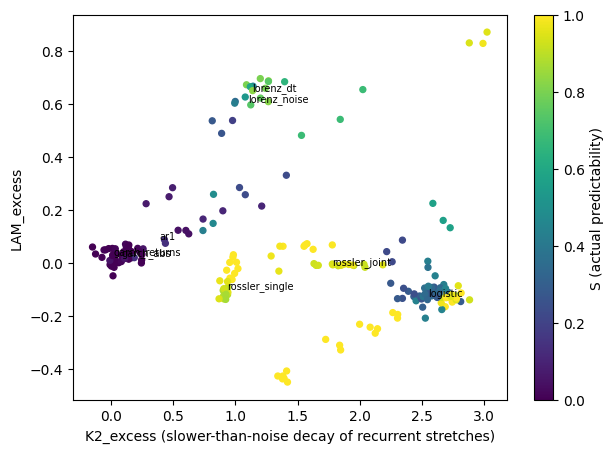

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(results["K2_excess"], results["LAM_excess"], c=results["S"], cmap="viridis", s=18)
for fam, g in results.groupby("family"):
    ax.annotate(fam, (g["K2_excess"].median(), g["LAM_excess"].median()), fontsize=7)
ax.set(xlabel="K2_excess (slower-than-noise decay of recurrent stretches)", ylabel="LAM_excess")
plt.colorbar(sc, label="S (actual predictability)"); plt.show()

## Joint vs single recurrence: coupled Rössler

Standard Rössler (a = b = 0.2, c = 5.7), frequency mismatch ±0.02, sampled every 1 time unit. `rossler_single` uses x₁ only; `rossler_joint` uses the joint RP of x₁ and x₂ (each thresholded at 5%), with the joint state as forecast target. The shuffled joint RP is too sparse (RR ≈ 0.25%) for a decay estimate, so `K2_excess` is undefined for the joint case and it is left out of the leave-one-family-out fit.

In [10]:
ros = (results[results.family.str.startswith("rossler")]
       .groupby(["family", "param"])[["phase_locking", "RR", "DET", "K2_lines", "K2_excess", "S"]].mean()
       .unstack(0))
display(ros.round(3))

phase_locking                           RR                 \
family rossler_joint rossler_single rossler_joint rossler_single   
param                                                              
0.00           0.029          0.038         0.002           0.05   
0.01           0.105          0.105         0.002           0.05   
0.02           0.230          0.230         0.003           0.05   
0.03           0.392          0.402         0.004           0.05   
0.04           0.719          0.715         0.008           0.05   
0.06           0.976          0.976         0.039           0.05   
0.08           0.984          0.984         0.043           0.05   
0.10           0.989          0.979         0.042           0.05   

                 DET                     K2_lines                 \
family rossler_joint rossler_single rossler_joint rossler_single   
param                                                              
0.00           0.874          0.953         0.286          0.094   
0.01           0.848          0.944         0.309          0.135   
0.02           0.860          0.940         0.257          0.143   
0.03           0.879          0.941         0.219          0.138   
0.04           0.889          0.941         0.176          0.132   
0.06           0.973          0.936         0.076          0.093   
0.08           0.975          0.943         0.092          0.097   
0.10           0.965          0.936         0.122          0.139   

           K2_excess                            S                 
family rossler_joint rossler_single rossler_joint rossler_single  
param                                                             
0.00           1.841          0.959         0.921          0.999  
0.01           1.875          0.934         0.917          0.954  
0.02           1.757          0.917         0.933          0.915  
0.03           1.939          0.920         0.950          0.873  
0.04           1.909          0.920         0.967          0.877  
0.06           1.659          0.978         0.995          0.998  
0.08           1.498          0.995         0.999          0.999  
0.10           1.331          0.887         0.976          0.956

## Window-size sweep

Same cases and the same predictability target, which is always computed on the full 1,000-point test window. Only the recurrence measures are recomputed, on the first W points: W = 150, 250, 500, 1000. A `K2_lines` value that cannot be estimated (fewer than 3 line lengths with ≥ 10 counts) is set to the white-noise value −ln RR, because that is what an unestimable decay means.

In [11]:
WINDOWS = [150, 250, 500, 1000]

def sweep_case(c):
    x, lam = generate(c)
    m, tau = c["m"], c["tau"]
    train, window = x[:TRAIN], x[TRAIN:TRAIN + WINDOW + HORIZON]
    joint, ross = c["family"] == "rossler_joint", c["family"].startswith("rossler")
    cols = [0, 2] if joint else [0]
    skill = analogue_skill(train[:, cols], window[:, cols], m, tau) if ross else analogue_skill(train, window, m, tau)
    if c["family"] == "ar1": skill = ar1_theory_skill(c["param"])
    elif c["family"] == "garch_returns": skill = np.zeros(HORIZON)
    elif c["family"] == "garch_abs": skill = garch_oracle_skill(c["param"])
    S = float(np.clip(skill, 0, None).mean())
    rows = []
    for W in WINDOWS:
        w = window[:W]
        if joint: R = joint_matrix([embed(w[:, 0], m, tau), embed(w[:, 2], m, tau)])
        elif ross: R = recurrence_matrix(embed(w[:, 0], m, tau))
        else: R = recurrence_matrix(embed(w, m, tau))
        rows.append(dict(c, W=W, S=S, lam_per_step=lam, **rqa(R)))
    return rows

t0 = time.time()
sweep = pd.DataFrame([r for c in cases() for r in sweep_case(c)])
sweep["K2_missing"] = sweep["K2_lines"].isna()
sweep["K2_lines"] = sweep["K2_lines"].fillna(-np.log(RR_TARGET))
sweep["group"] = sweep["family"].str.replace("_single|_joint", "", regex=True).str.replace("_noise|_dt", "", regex=True)
sweep.to_csv("../../results/tables/det_predictability_window_sweep.csv", index=False)
print(f"{len(sweep)} rows in {time.time() - t0:.0f} s")
display(sweep.groupby(["W", "family"])["K2_missing"].mean().unstack(0).loc[lambda t: t.sum(1) > 0].round(2))

def leave_family_out(df, cols):
    df = df[df.family != "rossler_joint"]
    preds = pd.Series(index=df.index, dtype=float)
    for grp in df.group.unique():
        tr, te = df[df.group != grp], df[df.group == grp]
        coef = lstsq(np.c_[np.ones(len(tr)), tr[cols]], tr["S"], rcond=None)[0]
        preds[te.index] = np.c_[np.ones(len(te)), te[cols]] @ coef
    return {g: preds[d.index].corr(d["S"], method="spearman") for g, d in df.groupby("group") if d["S"].nunique() > 1}

sets = {"K2_lines": ["K2_lines"], "DET + DET3/DET2": ["DET", "DET3_DET2"], "DET": ["DET"],
        "DET + LAM": ["DET", "LAM"], "DET + ENTR": ["DET", "ENTR"]}
lfo = pd.DataFrame({(W, name): leave_family_out(g, cols) for W, g in sweep.groupby("W") for name, cols in sets.items()}).T
lfo["mean"] = lfo.mean(1)
display(lfo["mean"].unstack(0).round(2))
display(lfo.xs("K2_lines", level=1).round(2))

within = (sweep.groupby(["W", "family"])[["DET", "LAM", "K2_lines", "DET3_DET2", "S"]]
          .apply(lambda g: pd.Series({k: g[k].corr(g["S"], method="spearman") for k in ["DET", "LAM", "K2_lines", "DET3_DET2"]}))
          .unstack(0).round(2))
display(within)
noise = sweep.groupby("W").apply(lambda g: g.groupby(["family", "param"])[["DET", "K2_lines"]].std().mean(), include_groups=False)
display(noise.rename(columns=lambda c: c + " seed SD").round(3))

852 rows in 165 s


W,150,250,500,1000
family,,,,
ar1,0.75,0.42,0.04,0.0
rossler_joint,0.29,0.00,0.00,0.0


,150,250,500,1000
DET,0.70,0.64,0.70,0.74
DET + DET3/DET2,0.70,0.62,0.74,0.81
DET + ENTR,0.57,0.49,0.49,0.56
DET + LAM,0.64,0.59,0.65,0.69
K2_lines,0.70,0.78,0.83,0.88


,ar1,garch_abs,logistic,lorenz,rossler,mean
150,0.72,0.76,0.92,0.89,0.19,0.70
250,0.87,0.58,0.91,0.96,0.57,0.78
500,0.97,0.59,0.95,0.95,0.67,0.83
1000,0.97,0.85,0.96,0.98,0.66,0.88


C:\Users\skous\AppData\Local\Programs\Python\Python312\Lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


DET                     LAM                   K2_lines        \
W               150   250   500   1000  150   250   500   1000     150   250    
family                                                                          
ar1             0.93  0.96  0.99  0.99  0.92  0.97  0.96  0.99    -0.72 -0.87   
garch_abs       0.74  0.45  0.43  0.78  0.14  0.30  0.43  0.62    -0.76 -0.58   
garch_returns    NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN      NaN   NaN   
logistic        0.68  0.63  0.69  0.67 -0.48 -0.64 -0.72 -0.75    -0.92 -0.91   
lorenz_dt       0.97  0.95  0.95  0.93  0.87  0.93  0.93  0.92    -0.85 -0.93   
lorenz_noise    0.96  0.97  0.97  0.97  0.63  0.84  0.82  0.88    -0.92 -0.95   
rossler_joint   0.77  0.79  0.81  0.89  0.84  0.83  0.70  0.62    -0.87 -0.93   
rossler_single  0.17  0.20  0.42  0.29  0.87  0.88  0.89  0.90    -0.19 -0.57   

                           DET3_DET2                    
W               500   1000      150   250   500   1000  
family                                                  
ar1            -0.97 -0.97      0.80  0.74  0.86  0.95  
garch_abs      -0.59 -0.85      0.74  0.50  0.74  0.76  
garch_returns    NaN   NaN       NaN   NaN   NaN   NaN  
logistic       -0.95 -0.96      0.94  0.93  0.95  0.96  
lorenz_dt      -0.92 -0.90      0.88  1.00  0.87  0.88  
lorenz_noise   -0.97 -0.98      0.90  0.86  0.80  0.81  
rossler_joint  -0.87 -0.91      0.39  0.74  0.71  0.85  
rossler_single -0.67 -0.66      0.11 -0.05  0.29  0.58

,DET seed SD,K2_lines seed SD
W,,
150,0.034,0.090
250,0.023,0.063
500,0.017,0.052
1000,0.010,0.029


## Findings (3 seeds, 213 cases, RR = 5%, window = 1,000, Euclidean)

**Sanity checks pass.** For IID data `K2_lines` = 2.96 (theory −ln 0.05 = 3.00). At r = 4 the logistic map gives `K2_lines` = 0.693 = ln 2. The analogue forecaster finds no skill in white noise or GARCH returns, and slightly underestimates the AR(1) optimum (S_knn 0.55 vs 0.68 at φ = 0.99), so it is a conservative target.

1. **The useful "DET combination" is DET measured at several minimum line lengths.** `K2_lines`, the rate at which recurrent stretches die out as they are required to be longer, ranked settings correctly inside every held-out family: AR 0.97, GARCH |r| 0.85, logistic 0.96, Lorenz 0.98, Rössler 0.68; mean ρ = 0.89. The two-point version `DET + DET3/DET2` came second (mean ρ = 0.84).
2. **DET alone is weaker** (mean ρ = 0.79) and fails on the logistic map (ρ = 0.67), where it stays at 0.65–0.80 across all chaotic r.
3. **Adding LAM or ENTR to DET does not help** (mean ρ 0.78 and 0.72). LAM's main value is elsewhere (point 6).
4. **Ranking transfers, scale does not.** Out-of-family RMSE is 0.25–0.39 for the recurrence features, so a model fitted on some systems puts the others on the wrong level. `K2_lines` per step also matches λ only for the logistic map; for Lorenz it is about 3.5× λ at this window and threshold. Treat it as a ranking index, not a calibrated λ estimate. (`DET + L` blows up out of family because L is unbounded for periodic orbits.)
5. **The shuffle correction made things worse here.** `*_excess` versions ranked logistic settings poorly (ρ ≈ −0.07): shuffling a periodic orbit with few distinct values produces exact ties and chance lines. With m = 1 the raw `K2_lines` already has a fixed noise reference (−ln RR).
6. **Single vs joint (coupled Rössler).**
   - x₁ alone becomes *less* predictable under weak coupling (S 0.999 → 0.873 at μ = 0.03) because an unobserved driver acts on it. Predictability returns at phase locking (μ ≥ 0.06).
   - Single DET is flat (≈ 0.94) and misses this; single LAM tracks it (ρ = 0.90).
   - The joint RP tracks the joint state: joint RR rises from 0.004 to 0.039 at phase locking, joint DET from 0.87 to 0.97, joint `K2_lines` falls from 0.29 to 0.08 (ρ with joint skill: 0.89 and −0.91).
7. **Finance warning (GARCH returns).** Direction is unpredictable by construction (S = 0), yet DET and `K2_lines` still move with volatility persistence (DET 0.386 → 0.415). On raw returns these measures report volatility structure, not return predictability.
8. **Permutation entropy, the established predictability baseline, does worse out of family** (mean ρ = 0.52); it fails on GARCH |r| and Rössler.

9. **Window size (sweep section).** `K2_lines` improves steadily with window length: leave-one-family-out mean ρ is 0.70 at W = 150, 0.78 at 250, 0.83 at 500 and 0.88 at 1,000. DET alone stays at 0.64–0.74 at every size, so the advantage of the multi-length measure only appears from about 250 points.
   - At W = 150 the decay cannot be estimated for 75% of AR cases (42% at 250, 4% at 500), because noise-like windows contain too few long lines.
   - The seed-to-seed SD of `K2_lines` halves from 0.090 to 0.029 between W = 150 and 1,000; DET's SD goes from 0.034 to 0.010.
   - The logistic and Lorenz rankings already hold at W = 150 (ρ ≈ 0.9). AR, GARCH |r| and Rössler need W ≥ 500.

**Limits.**
- One recurrence rate, one window length, Euclidean distance only, 3 seeds.
- The target is skill per *step*. Finer sampling therefore counts as more predictable, which hides the oversampling trap from Marwan (2011).
- `K2_lines` needs ≥ 3 line lengths with ≥ 10 counts, so short or noise-like windows, and the shuffled joint RP, give no estimate.

**Next.** Sweep RR (2–20%); compare Euclidean vs β geometry; repeat with skill per time unit; and compare against a CNN on the full (joint) RP.